nov 23

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import pandas as pd
import numpy as np

import geopandas as gpd
from shapely import wkt

In [4]:
# calgary = pd.read_csv('..\\..\\data\\ecm1\\City_Boundary_20261005.csv')

# print(calgary.columns.tolist())   # find the column holding the geometry text

# calgary['geometry'] = calgary['MULTIPOLYGON'].apply(wkt.loads)

# gdf = gpd.GeoDataFrame(calgary, geometry='geometry', crs='EPSG:4326')

In [5]:
# rm = gpd.read_file('..\\..\\data\\lpr_000b16a_e\\prov_shp\\lpr_000b16a_e.shp')

# print(rm.columns.tolist())   # find the column holding the geometry text
# print(rm.crs)                      # likely EPSG:3347 (Lambert), not lon/lat

# rm = rm.to_crs(epsg=4326)          # convert to lon/lat to match your grid

In [6]:
dt = pd.read_csv('..\\..\\data\\ecm1\\ecm1_fullmodel_novel.csv', header=None, skiprows=1,
                names=['num', 'long', 'lat', 'hcc','sed','hc','type','z1','z2', 'z3','th1', 'th2', 'th3','rho1', 'rho2', 'rho3', 'rho_man'])
print(dt)

         num   long   lat      hcc     sed       hc  type       z1       z2  \
0          1 -179.5  89.5   6.4459  2.3303   8.7762  SOCE   4.4574   6.5846   
1          2 -178.5  89.5   6.3511  2.3344   8.6854  SOCE   4.4302   6.5261   
2          3 -177.5  89.5   6.2512  2.3398   8.5910  SOCE   4.4027   6.4656   
3          4 -176.5  89.5   6.1516  2.3463   8.4980  SOCE   4.3764   6.4064   
4          5 -175.5  89.5   6.0578  2.3520   8.4098  SOCE   4.3510   6.3501   
...      ...    ...   ...      ...     ...      ...   ...      ...      ...   
64795  64796  175.5 -89.5  39.0010  0.0000  39.0010  PLAT  12.8703  25.7406   
64796  64797  176.5 -89.5  39.0014  0.0000  39.0014  PLAT  12.8705  25.7409   
64797  64798  177.5 -89.5  39.0018  0.0000  39.0018  PLAT  12.8706  25.7412   
64798  64799  178.5 -89.5  39.0023  0.0000  39.0023  PLAT  12.8708  25.7415   
64799  64800  179.5 -89.5  39.0029  0.0000  39.0029  PLAT  12.8709  25.7419   

            z3      th1      th2      th3      rho1

crs='EPSG:4326': long/lat in degrees

In [7]:
d_jdf= dt[dt['long'].between(-131, -119) & dt['lat'].between(37, 52)]

In [8]:
d_jdf_grid_hcc = d_jdf.pivot(index='lat', columns='long', values='hcc')
lat_jdf = d_jdf_grid_hcc.index.values; long_jdf = d_jdf_grid_hcc.columns.values; hcc_jdf = d_jdf_grid_hcc.values

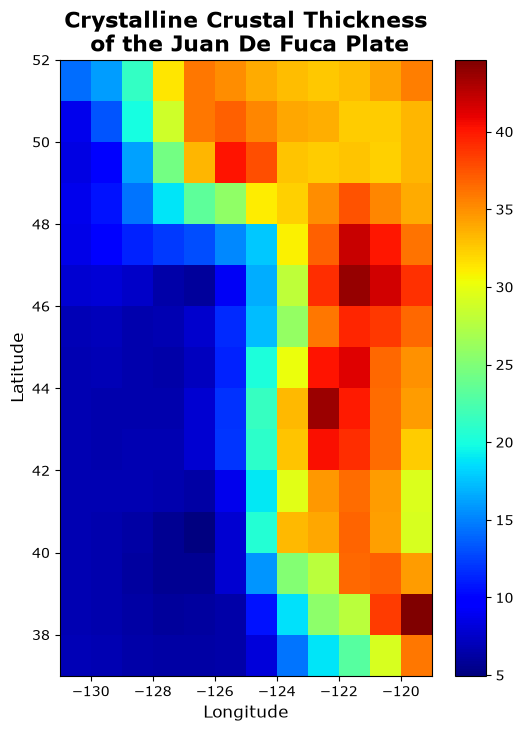

In [23]:
fig, ax = plt.subplots(figsize=(6, 8))

# plt.rcParams['font.family'] = 'Verdana'


pcm_jdf = ax.pcolormesh(long_jdf, lat_jdf, hcc_jdf, cmap='jet')

cbar = fig.colorbar(pcm_jdf, ax=ax)

# ax5.set_aspect('auto')

# actually showing the Crystalline Crustal Thickness Below Calgary, AB

plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)

ax.set_title('Crystalline Crustal Thickness\n of the Juan De Fuca Plate', fontsize=16, fontweight='bold')

# plt.savefig('..\\..\\figures\\ecm1\\B_nov15.png', dpi=400, bbox_inches='tight')
plt.show()